In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
# %load_ext cuml.accel
# %load_ext cudf.pandas

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep
from threadpoolctl import threadpool_limits

## -- Machine Learning --
from sklearn.linear_model import LogisticRegression

from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

TARGET, ID = 'is_fraud', 'id'

## -- Check if id is unique --
if ID in train.columns:
    if train.id.is_unique:
        print(f"Train ID column is unique: {train.id.is_unique}... Dropping!")
        train = train.drop(columns=[ID])
        test  = test.drop(columns=[ID])
        if ID in orig.columns:
            orig = orig.drop(columns=[ID])

Train ID column is unique: True... Dropping!


In [7]:
# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET]]
bool_cols = [c for c in bol if c not in [TARGET]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
base_cols = [c for c in train.columns if c not in [TARGET]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name:5s} shape: {df.shape}")
    
print(f"\nDataFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test  shape: (299984, 24)
Orig  shape: (20000, 25)

DataFrame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [8]:
float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    # 'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [9]:
train_len = len(train)
test_len  = len(test)

n_unique = train[base_cols].nunique().sort_values()
n_unique

used_vpn                            2
ip_country_mismatch                 2
is_ai_generated_scam_attempt        2
billing_shipping_mismatch           2
is_foreign_transaction              2
is_new_merchant                     2
cvv_retry_count                     4
prior_disputes                      5
auth_method                         5
channel                             5
card_type                           5
day_of_week                         7
device_type                         8
txn_count_last_24h                 12
merchant_category                  12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

In [10]:
def get_class_weights(y):
    """
    y: Current y_labels -> array_like or series
    """
    weights_ = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return weights_

def get_sample_weights(y, y_true):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    """
    classes_ = np.unique(y_true)
    weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
    class_weights = dict(zip(classes_, weights_))
    return np.array([class_weights[label] for label in y])

print("- Helper Functions Ready -")

- Helper Functions Ready -


# FEATURE ENGINEERING

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [12]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = orig.groupby(col)[target].mean().reset_index(name=new_col)
                    elif agg_key == 'median':
                        map_df = orig.groupby(col)[target].median().reset_index(name=new_col)
                    elif agg_key == 'count':
                        map_df = orig.groupby(col).size().reset_index(name=new_col)
                    elif agg_key == 'nunique':
                        map_df = orig.groupby(col)[target].nunique().reset_index(name=new_col)
                    elif agg_key == 'std':
                        map_df = orig.groupby(col)[target].std().reset_index(name=new_col)
                    elif agg_key == 'skew':
                        map_df = orig.groupby(col)[target].skew().reset_index(name=new_col)
                    elif agg_key == 'max':
                        map_df = orig.groupby(col)[target].max().reset_index(name=new_col)
                    elif agg_key == 'min':
                        map_df = orig.groupby(col)[target].min().reset_index(name=new_col)
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [13]:
# ## -- Cyclic encoding --
# CYCLICS = []

# for col in ['MonthlyCharges', 'TotalCharges']:
#     for p in [12, 30]:
#         n_s = f'{col}_sin_{p}'
#         n_c = f'{col}_cos_{p}'
#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')

#         test[n_s] = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')

#         orig[n_s] = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')

#         CYCLICS += [n_s, n_c]

# print(f"Cylcic Features created: {len(CYCLICS)}") 
# train[CYCLICS].head(3)

In [14]:
v = 3291.06
k = -2
for k in range(-2, 3):
    s = np.rint(v * 10**4) #.astype("int64")
    print(s // 10**(k+4) % 10, end=' | ')
    print(v // (10**k) % 10)

6.0 | 5.0
0.0 | 0.0
1.0 | 1.0
9.0 | 9.0
2.0 | 2.0


In [15]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

combined = pd.concat([train, test, orig], ignore_index=True)
digit_cols = []

for col in num_cols:
    scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
    for k in range(-2, 3):
        dig_col = f"{col}_DIGIT_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8') #.astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 37



account_balance_usd_DIGIT_-2      10
txn_count_last_24h_DIGIT_1         2
time_of_day_hour_DIGIT_0          10
time_of_day_hour_DIGIT_1           3
hours_since_last_txn_DIGIT_0      10
merchant_risk_score_DIGIT_1       10
amount_usd_DIGIT_-1               10
distance_from_home_km_DIGIT_-1    10
account_balance_usd_DIGIT_2       10
amount_usd_DIGIT_2                10
prior_disputes_DIGIT_0             5
account_balance_usd_DIGIT_1       10
customer_age_DIGIT_0              10
distance_from_home_km_DIGIT_0     10
hours_since_last_txn_DIGIT_-1     10
amount_usd_DIGIT_-2               10
card_age_months_DIGIT_0           10
merchant_risk_score_DIGIT_-2       2
merchant_risk_score_DIGIT_-1      10
card_age_months_DIGIT_1            6
hours_since_last_txn_DIGIT_-2     10
cvv_retry_count_DIGIT_0            4
hours_since_last_txn_DIGIT_1       6
amount_usd_DIGIT_1                10
merchant_risk_score_DIGIT_2        2
merchant_risk_score_DIGIT_0       10
velocity_score_DIGIT_-1           10
v

In [16]:
# ## -- Get NaN indicators --
# def appy_nan_indicator(df):
#     df1 = df.copy()
#     cols_with_nan = df1.columns[df1.isna().any()]
#     indicators = df1[cols_with_nan].isna().astype(float).add_prefix('isna_')
#     indi_cols = indicators.columns.tolist()
#     df1 = df1.join(indicators)

#     return df1, indi_cols

# train, INDI_COLS = appy_nan_indicator(train)
# test, _  = appy_nan_indicator(test)
# orig, _  = appy_nan_indicator(orig)
# print(INDI_COLS)

# # ## -- Fill categorical --
# # train[CATS] = train[CATS].fillna('missing')
# # test[CATS]  = test[CATS].fillna('missing')
# # orig[CATS]  = orig[CATS].fillna('missing')

# train

In [17]:
# plt.figure(figsize=(16, 12))
# sns.heatmap(train.select_dtypes(include='number').corr(), annot=True, cbar=False, fmt='.2f', center=0)

# # plt.tight_layout()
# plt.show()

In [18]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig], ignore_index=True)
## ------------------------------------------------------------
# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols #[c for c in num_cols if train[c].nunique() > 100]

for c in tqdm(select_nc, desc="nums_to_cats"):
    n_cat = f"{c}_cat_"
    combined[n_cat], _ = pd.factorize(combined[c], sort=True)
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(n_cat)
FEATURES = list(set(FEATURES + nums_to_cats))
## ------------------------------------------------------------
## -- Factorize cat_cols --
for c in tqdm(cat_cols+bool_cols, desc="factorize_cats"): # + INTER + new_cats
    combined[c], _ = pd.factorize(combined[c], sort=True)

# for c in tqdm(cat_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len] #[FEATURES+[TARGET]]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 61


nums_to_cats:   0%|          | 0/13 [00:00<?, ?it/s]

factorize_cats:   0%|          | 0/11 [00:00<?, ?it/s]

Total features after operation: 74


In [19]:
## -- Frequency encoding --
freq_cols = []
select_freq = num_cols
# [c for c in base_cols if train[c].nunique() > 2]

combined = pd.concat([train, test], ignore_index=True)

print("\nCreating frequencies (Safe Global Mapping)...")
for col in select_freq:
    # Calculate frequencies using ONLY train
    freq_map = combined[col].value_counts(dropna=False, normalize=True).to_dict()

    n = f"{col}_FREQ"
    print(f"⧗ {n}", end="")

    # Map the training-derived frequencies across all datasets safely
    # If a category exists in 'test' but wasn't in train/orig, .map() turns it into NaN. 
    # Using .fillna(1) handles unseeen test categories cleanly.
    train[n] = train[col].map(freq_map).fillna(0).astype("float32")
    test[n] = test[col].map(freq_map).fillna(0).astype("float32")
    orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

    freq_cols.append(n)
    print()

# num_cols = list(set(num_cols + freq_cols))
FEATURES = list(set(FEATURES + freq_cols))

print(f"\n *** Total frequency features: {len(freq_cols)}")

train[freq_cols].head()


Creating frequencies (Safe Global Mapping)...
⧗ amount_usd_FREQ
⧗ hours_since_last_txn_FREQ
⧗ txn_count_last_24h_FREQ
⧗ distance_from_home_km_FREQ
⧗ card_age_months_FREQ
⧗ customer_age_FREQ
⧗ account_balance_usd_FREQ
⧗ cvv_retry_count_FREQ
⧗ velocity_score_FREQ
⧗ time_of_day_hour_FREQ
⧗ day_of_week_FREQ
⧗ merchant_risk_score_FREQ
⧗ prior_disputes_FREQ

 *** Total frequency features: 13


,amount_usd_FREQ,hours_since_last_txn_FREQ,txn_count_last_24h_FREQ,distance_from_home_km_FREQ,card_age_months_FREQ,customer_age_FREQ,account_balance_usd_FREQ,cvv_retry_count_FREQ,velocity_score_FREQ,time_of_day_hour_FREQ,day_of_week_FREQ,merchant_risk_score_FREQ,prior_disputes_FREQ
0,0.000013,0.000339,0.132745,0.000721,0.072014,0.018489,0.000059,0.917328,0.001522,0.044080,0.139514,0.003115,0.854653
1,0.000372,0.002018,0.254781,0.000039,0.019152,0.015722,0.000289,0.917328,0.001710,0.040134,0.135366,0.002941,0.137833
2,0.000258,0.000333,0.188648,0.000553,0.057276,0.020817,0.000056,0.917328,0.001185,0.046935,0.143550,0.001628,0.854653
3,0.000226,0.000278,0.188648,0.000662,0.072014,0.019499,0.000051,0.917328,0.004245,0.042621,0.139514,0.003333,0.854653
4,0.000027,0.002045,0.188648,0.000443,0.013746,0.018086,0.000053,0.917328,0.001188,0.039240,0.146337,0.002919,0.854653


In [20]:
n = 138.73

str(n).split('.')

['138', '73']

In [21]:
## -- Create leading features --

lead_cols = []
combined = pd.concat([train, test, orig], ignore_index=True)

for c in float_cols:
    lead1 = f"{c}_INT"
    lead2 = f"{c}_DEC"
    leadk = f"{c}_LEAD_K"

    # Convert to string and split across the decimal point for each row
    split_df = combined[c].astype(str).str.split('.', expand=True)

    # If a number has no decimal point, expand=True might only create 1 column.
    # We guarantee column 1 exists by filling it if missing.
    if 1 not in split_df.columns:
        split_df[1] = '0'

    combined[lead1] = split_df[0]
    combined[lead2] = split_df[1].fillna('0')

    # Use .str.len() for element-wise string lengths 
    # and element-wise string concatenation
    int_len = split_df[0].str.len().astype(str)
    dec_len = combined[lead2].str.len().astype(str)

    combined[leadk] = int_len + '_|_' + dec_len
    lead_cols.extend([lead1, lead2, leadk])

for c in tqdm(lead_cols, desc="factorize_lead_cols"):
    combined[c], _ = pd.factorize(combined[c], sort=True)

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

# Check nunique, and find which ones are < 2
unique_counts = train[lead_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update list for keep
lead_cols = [i for i in lead_cols if i not in drop_cols]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"\n*** Total lead features: {len(lead_cols)}")

print(train[lead_cols].nunique(dropna=False))
train[lead_cols].head()

factorize_lead_cols:   0%|          | 0/18 [00:00<?, ?it/s]


*** Total lead features: 18
amount_usd_INT                  1144
amount_usd_DEC                   100
amount_usd_LEAD_K                  8
account_balance_usd_INT         4928
account_balance_usd_DEC          100
account_balance_usd_LEAD_K         7
hours_since_last_txn_INT          51
hours_since_last_txn_DEC         100
hours_since_last_txn_LEAD_K        4
distance_from_home_km_INT         56
distance_from_home_km_DEC        100
distance_from_home_km_LEAD_K       4
velocity_score_INT                73
velocity_score_DEC                10
velocity_score_LEAD_K              2
merchant_risk_score_INT           98
merchant_risk_score_DEC           11
merchant_risk_score_LEAD_K         4
dtype: int64


,amount_usd_INT,amount_usd_DEC,amount_usd_LEAD_K,account_balance_usd_INT,account_balance_usd_DEC,account_balance_usd_LEAD_K,hours_since_last_txn_INT,hours_since_last_txn_DEC,hours_since_last_txn_LEAD_K,distance_from_home_km_INT,distance_from_home_km_DEC,distance_from_home_km_LEAD_K,velocity_score_INT,velocity_score_DEC,velocity_score_LEAD_K,merchant_risk_score_INT,merchant_risk_score_DEC,merchant_risk_score_LEAD_K
0,1097,16,4,777,35,5,70,77,1,65,78,3,45,6,0,23,3,1
1,613,83,4,3506,0,4,1,54,1,35,6,3,27,5,1,23,10,1
2,1083,36,1,170,88,5,1,20,0,142,17,1,29,9,1,18,1,1
3,818,44,4,2333,67,5,45,13,1,142,67,1,13,8,1,37,10,1
4,1144,85,6,3563,6,5,0,80,0,13,69,3,28,9,1,44,0,1


In [22]:
# ## -- Create leading features --

# lead_cols = []

# combined = pd.concat([train, test, orig], ignore_index=True)

# for c in float_cols:
#     lead1 = f"{c}_LEAD_1"
#     lead2 = f"{c}_LEAD_2"
#     leadk = f"{c}_LEAD_K"

#     # Convert to string and split across the decimal point for each row
#     split_df = combined[c].astype(str).str.split('.', expand=True)

#     if 1 not in split_df.columns:
#         split_df[1] = '0'

#     combined[lead1] = split_df[0]
#     combined[lead2] = split_df[1].fillna('0')

#     # Get raw lengths
#     int_len_ser = split_df[0].str.len()
#     dec_len_ser = combined[lead2].str.len()

#     # ADJUSTMENT: If the value itself is exactly '0', force its recorded length to 0
#     int_len = int_len_ser.where(split_df[0] != '0', 0).astype(str)
#     dec_len = dec_len_ser.where(combined[lead2] != '0', 0).astype(str)
    
#     combined[leadk] = int_len + "_|_" + dec_len

#     l1.append(lead1); l2.append(lead2); lk.append(leadk)
#     lead_cols.extend([lead1, lead2, leadk])

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# # Check nunique, and find which ones are < 2
# unique_counts = train[lead_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update list for keep
# lead_cols = [i for i in lead_cols if i not in drop_cols]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"\n*** Total lead features: {len(lead_cols)}")

# print(train[lead_cols].nunique(dropna=False))
# train[lead_cols].head()

In [23]:
v = 254767.85
for f in [1, 10, 100, 1000, 10000]:
    print(f"{f:>5}: {v // f}")

    1: 254767.0
   10: 25476.0
  100: 2547.0
 1000: 254.0
10000: 25.0


In [24]:
# ## -- Create floor features --
# floor_cols = []

# combined = pd.concat([train, test, orig], ignore_index=True)

# for f in tqdm([100, 1000], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in float_cols:
#         f_name = f"{c}_FLOOR_{f}"
#         combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
#         # print(f" ⧗ {f_name}", end='... ')
#         # print(combined[f_name].nunique())
#         floor_cols.append(f_name)

# # for f in tqdm([1000], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Flight Distance']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('float32')
# #         floor_cols.append(f_name)
# #         print()

# # for f in tqdm([10], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Age']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# # combined['age10_X_dist250'] = combined['Age_//_10'] * combined['Flight Distance_//_250']

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# # Check nunique, and find which ones are < 2
# unique_counts = train[floor_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# floor_cols = [i for i in set(floor_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"\n*** Total floor features: {len(floor_cols)}")

# print(train[floor_cols].nunique(dropna=False))

In [25]:
## -- Create floor features --
round_cols = []

combined = pd.concat([train, test, orig], ignore_index=True)

for c in tqdm(float_cols, desc='Rounding'):
    # print(f, end='-> ')
    for f in [0]:
        r_name = f"{c}_ROUND_{f}"
        combined[r_name] = combined[c].round(f)
        # print(f" ⧗ {f_name}", end='... ')
        # print(combined[f_name].nunique())
        round_cols.append(r_name)

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

# Check nunique, and find which ones are < 2
unique_counts = train[round_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
round_cols = [i for i in round_cols if i not in drop_cols]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"\n*** Total floor features: {len(round_cols)}")

print(train[round_cols].nunique(dropna=False))

Rounding:   0%|          | 0/6 [00:00<?, ?it/s]


*** Total floor features: 6
amount_usd_ROUND_0               1288
account_balance_usd_ROUND_0      5387
hours_since_last_txn_ROUND_0       53
distance_from_home_km_ROUND_0      57
velocity_score_ROUND_0             73
merchant_risk_score_ROUND_0       100
dtype: int64


In [26]:
def digit_keys(df1, cols=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

train, digit_cols2 = digit_keys(train)
test, _ = digit_keys(test)

print(train.shape, test.shape)
train.head()

(699960, 148) (299984, 147)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,amount_usd_DIGIT_-2,amount_usd_DIGIT_-1,amount_usd_DIGIT_0,amount_usd_DIGIT_1,amount_usd_DIGIT_2,hours_since_last_txn_DIGIT_-2,hours_since_last_txn_DIGIT_-1,hours_since_last_txn_DIGIT_0,hours_since_last_txn_DIGIT_1,txn_count_last_24h_DIGIT_0,txn_count_last_24h_DIGIT_1,distance_from_home_km_DIGIT_-2,distance_from_home_km_DIGIT_-1,distance_from_home_km_DIGIT_0,distance_from_home_km_DIGIT_1,card_age_months_DIGIT_0,card_age_months_DIGIT_1,customer_age_DIGIT_0,customer_age_DIGIT_1,account_balance_usd_DIGIT_-2,account_balance_usd_DIGIT_-1,account_balance_usd_DIGIT_0,account_balance_usd_DIGIT_1,account_balance_usd_DIGIT_2,cvv_retry_count_DIGIT_0,...,distance_from_home_km_DEC,distance_from_home_km_LEAD_K,velocity_score_INT,velocity_score_DEC,velocity_score_LEAD_K,merchant_risk_score_INT,merchant_risk_score_DEC,merchant_risk_score_LEAD_K,amount_usd_ROUND_0,account_balance_usd_ROUND_0,hours_since_last_txn_ROUND_0,distance_from_home_km_ROUND_0,velocity_score_ROUND_0,merchant_risk_score_ROUND_0,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,0.0,6,1,1,6,0,7,7,9,0,1,0,8,7,7,1,8,4,6,5,5,3,9,6,2,0,...,78,3,45,6,0,23,3,1,61.0,1269.0,10.0,18.0,6.0,29.0,61,6,611,16,26,261,1269,126,12693,35,41,412,9,0,97,77,19,109,17,1,177,78,21,217,5,0,55,50,15,105,29,2,292,20,22,229
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,0.0,3,8,4,2,0,4,5,1,0,3,0,6,0,3,1,8,3,8,2,0,0,3,3,2,0,...,6,3,27,5,1,23,10,1,25.0,3233.0,2.0,13.0,33.0,30.0,24,2,248,83,22,224,3233,323,32330,0,43,432,1,0,15,54,11,101,13,1,130,6,21,213,33,3,334,40,23,233,29,2,299,90,22,229
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,0.0,6,3,6,0,0,0,2,1,0,4,0,7,1,8,0,0,5,5,5,8,8,6,4,0,0,...,17,1,29,9,1,18,1,1,6.0,1047.0,1.0,8.0,36.0,24.0,6,0,63,36,16,106,1046,104,10468,88,41,410,1,0,12,20,11,101,8,0,81,17,18,108,35,3,358,80,23,235,24,2,241,10,22,224
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,0.0,4,4,7,3,0,3,1,5,0,4,0,7,6,8,0,8,4,8,4,7,6,7,1,2,0,...,67,1,13,8,1,37,10,1,37.0,2218.0,5.0,9.0,21.0,42.0,37,3,374,44,23,237,2217,221,22176,67,42,422,5,0,51,13,15,105,8,0,86,67,18,108,20,2,207,70,22,220,41,4,419,90,24,241
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,1,4,0,3,6,0,0,0,0,0,0,0.0,5,8,3,5,6,0,8,0,0,4,0,9,6,1,1,7,3,2,5,6,0,1,9,2,0,...,69,3,28,9,1,44,0,1,654.0,3291.0,1.0,12.0,35.0,48.0,653,65,6538,85,36,365,3291,329,32910,6,43,432,0,0,8,80,10,100,11,1,116,69,21,211,34,3,348,80,23,234,48,4,480,0,24,248


In [27]:
## -- POLYNOMIAL features --
combined = pd.concat([train, test, orig], ignore_index=True)

poly_cols = []

for c in tqdm(int_cols, desc='Polynomials'):
    sq_name = f"{c}_SQUARED"
    combined[sq_name] = combined[c] ** 2
    poly_cols.append(sq_name)

    cb_name = f"{c}_CUBED"
    combined[cb_name] = combined[c] ** 3
    poly_cols.append(cb_name)
print(f"\n*** Total poly features: {len(poly_cols)}")

## -- LOG float features --
log_cols = []

for c in tqdm(float_cols, desc='Square-root'):
    log_name = f"{c}_LOG"
    combined[log_name] = np.log1p(combined[c].values)
    log_cols.append(log_name)

    # sqrt_name = f"{c}_SQRT"
    # combined[sqrt_name] = np.sqrt(combined[c].values)
    # log_cols.append(sqrt_name)

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print(f"\n*** Total log/sqrt features: {len(log_cols)}")

Polynomials:   0%|          | 0/4 [00:00<?, ?it/s]


*** Total poly features: 8


Square-root:   0%|          | 0/6 [00:00<?, ?it/s]


*** Total log/sqrt features: 6


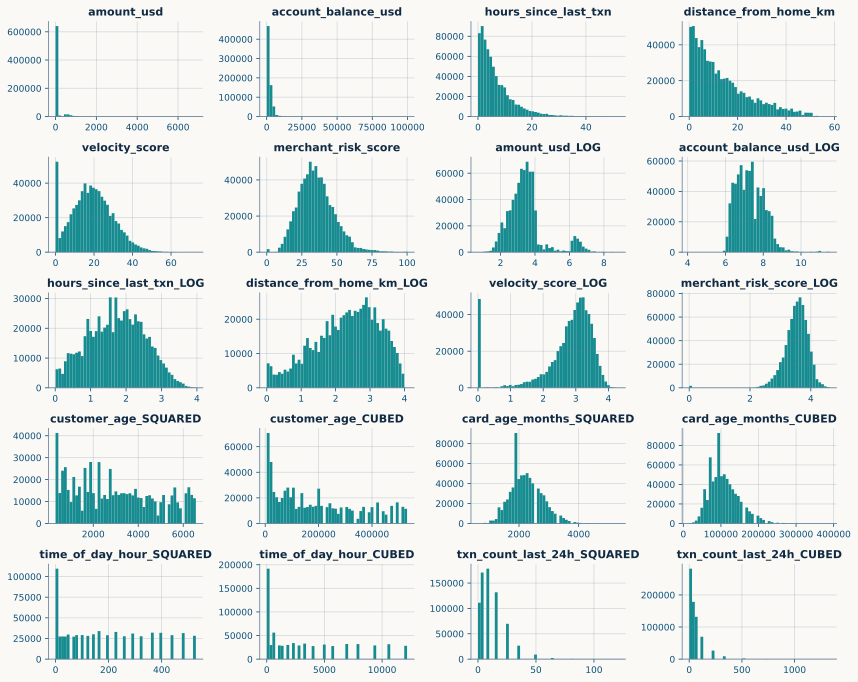

In [28]:
train[float_cols+log_cols+poly_cols].hist(figsize=(12, 15), layout=(8, 4), bins=50)
plt.tight_layout()
plt.show()

In [ ]:
_df = train[[c for c in train.columns if 'account' in c]]
display(_df.head())

cm = ['pearson', 'spearman'][0]
corr_df = _df.corr(cm)
plt.figure(figsize=(12, 6))
sns.heatmap(corr_df, mask=np.triu(corr_df), annot=True, fmt='.3f')

# plt.tight_layout()
plt.show()

In [30]:
# ## -- Create Bin features --
# bin_cols = []

# for c in tqdm(float_cols, desc='Binning'):
#     # print(f, end='-> ')
#     for q in [100]:
#         bin_name = f"{c}_BIN_{q}"
#         k_bin = KBinsDiscretizer(
#             n_bins=q,
#             encode='ordinal',
#             strategy='quantile',
#             subsample=None,
#             random_state=42,
#         )
#         k_bin.fit(train[[c]].fillna(0))

#         train[bin_name] = k_bin.transform(train[[c]].fillna(0))
#         test[bin_name]  = k_bin.transform(test[[c]].fillna(0))
#         orig[bin_name]  = k_bin.transform(orig[[c]].fillna(0))

#         bin_cols.append(bin_name)

# # Check nunique, and find which ones are < 2
# unique_counts = train[bin_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# bin_cols = [i for i in bin_cols if i not in drop_cols]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# print(f"\n*** Total bin features: {len(bin_cols)}")

# print(train[bin_cols].nunique(dropna=False))

In [31]:
# INTER = []

# combined = pd.concat([train, test, orig], ignore_index=True)

# ## ------------------------------------------------------------------------
# # combo_2_1 = list(itertools.combinations(cat_cols + bool_cols, 2)) # 
# # for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
# #     n_col = f"Bi_{c1}_X_{c2}"
# #     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
# #     combined[n_col], _ = pd.factorize(combo_string, sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# combo_3_1 = list(itertools.combinations(cat_cols + bool_cols, 3))
# for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
#     n_col = f"Tri_{c1}_X_{c2}_X_{c3}"
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
#     combined[n_col], _ = pd.factorize(combo_string, sort=True)
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)
# ## ------------------------------------------------------------------------

# for n_col in INTER:
#     train[n_col] = combined[n_col].iloc[:train_len].values
#     test[n_col]  = combined[n_col].iloc[train_len:train_len+test_len].values
#     orig[n_col]  = combined[n_col].iloc[train_len+test_len:].values

# print(f"Total Interaction Features: {INTER}")

# del combined
# gc.collect()

In [32]:
# # ==========================================
# # 2. HIGH-IMPACT DOMAIN INTERACTIONS (AUC BOOST) ⚠️
# # ==========================================

# combined = pd.concat([train, test, orig], ignore_index=True)

# service_cols = [
#     'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
#     'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
#     'Inflight entertainment', 'On-board service', 'Leg room service',
#     'Baggage handling', 'Checkin service', 'Cleanliness'
# ]

# # A. Total Delay & Delay Discrepancy
# # Tree models easily split on raw values, but explicit sums and differences reduce required tree depth
# # combined['Total_Delay'] = combined['Departure Delay in Minutes'].fillna(0) + combined['Arrival Delay in Minutes'].fillna(0)
# # combined['Delay_Recovered'] = combined['Departure Delay in Minutes'].fillna(0) - combined['Arrival Delay in Minutes'].fillna(0)
# # combined['Is_Delayed'] = (combined['Total_Delay'] > 0).astype('int8').astype('category')

# # B. Aggregated Service Experience Scores (Crucial for Passenger Satisfaction datasets)
# # Capturing the holistic experience mathematically
# combined['Total_Service_Score'] = combined[service_cols].sum(axis=1)
# combined['Mean_Service_Score'] = combined[service_cols].mean(axis=1)
# combined['Variance_Service_Score'] = combined[service_cols].var(axis=1).astype('float32')

# # Segmenting critical service groups
# booking_flow = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
# comfort_flow = ['Seat comfort', 'Food and drink', 'Leg room service', 'Cleanliness']
# combined['Digital_Experience_Score'] = combined[booking_flow].mean(axis=1)
# combined['Physical_Comfort_Score'] = combined[comfort_flow].mean(axis=1)

# # Count of zero-scores (often represents "Not Applicable" or an extreme pain point)
# combined['Count_Zero_Services'] = (combined[service_cols] == 0).sum(axis=1).astype('int8')

# # # C. Distance vs. Age Groupings
# # combined['Distance_per_Year_of_Age'] = combined['Flight Distance'] / (combined['Age'] + 1)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Arithmetric features ready")

In [33]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

print(f"Train shape {train.shape}")
train.head()

Train shape (699960, 162)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,amount_usd_DIGIT_-2,amount_usd_DIGIT_-1,amount_usd_DIGIT_0,amount_usd_DIGIT_1,amount_usd_DIGIT_2,hours_since_last_txn_DIGIT_-2,hours_since_last_txn_DIGIT_-1,hours_since_last_txn_DIGIT_0,hours_since_last_txn_DIGIT_1,txn_count_last_24h_DIGIT_0,txn_count_last_24h_DIGIT_1,distance_from_home_km_DIGIT_-2,distance_from_home_km_DIGIT_-1,distance_from_home_km_DIGIT_0,distance_from_home_km_DIGIT_1,card_age_months_DIGIT_0,card_age_months_DIGIT_1,customer_age_DIGIT_0,customer_age_DIGIT_1,account_balance_usd_DIGIT_-2,account_balance_usd_DIGIT_-1,account_balance_usd_DIGIT_0,account_balance_usd_DIGIT_1,account_balance_usd_DIGIT_2,cvv_retry_count_DIGIT_0,...,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,customer_age_SQUARED,customer_age_CUBED,card_age_months_SQUARED,card_age_months_CUBED,time_of_day_hour_SQUARED,time_of_day_hour_CUBED,txn_count_last_24h_SQUARED,txn_count_last_24h_CUBED,amount_usd_LOG,account_balance_usd_LOG,hours_since_last_txn_LOG,distance_from_home_km_LOG,velocity_score_LOG,merchant_risk_score_LOG
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,0.0,6,1,1,6,0,7,7,9,0,1,0,8,7,7,1,8,4,6,5,5,3,9,6,2,0,...,61.0,6.0,611.0,16.0,26.0,261.0,1269.0,126.0,12693.0,35.0,41.0,412.0,9.0,0.0,97.0,77.0,19.0,109.0,17.0,1.0,177.0,78.0,21.0,217.0,5.0,0.0,55.0,50.0,15.0,105.0,29.0,2.0,292.0,20.0,22.0,229.0,3136,175616,2304,110592,289,4913,1,1,4.129712,7.147048,2.376764,2.932792,1.871802,3.407842
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,0.0,3,8,4,2,0,4,5,1,0,3,0,6,0,3,1,8,3,8,2,0,0,3,3,2,0,...,24.0,2.0,248.0,83.0,22.0,224.0,3233.0,323.0,32330.0,0.0,43.0,432.0,1.0,0.0,15.0,54.0,11.0,101.0,13.0,1.0,130.0,6.0,21.0,213.0,33.0,3.0,334.0,40.0,23.0,233.0,29.0,2.0,299.0,90.0,22.0,229.0,784,21952,1444,54872,529,12167,9,27,3.251537,8.081475,0.932164,2.643334,3.538057,3.430756
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,0.0,6,3,6,0,0,0,2,1,0,4,0,7,1,8,0,0,5,5,5,8,8,6,4,0,0,...,6.0,0.0,63.0,36.0,16.0,106.0,1046.0,104.0,10468.0,88.0,41.0,410.0,1.0,0.0,12.0,20.0,11.0,101.0,8.0,0.0,81.0,17.0,18.0,108.0,35.0,3.0,358.0,80.0,23.0,235.0,24.0,2.0,241.0,10.0,22.0,224.0,3025,166375,2500,125000,225,3375,16,64,1.996060,6.954524,0.788457,2.215937,3.605498,3.222868
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,0.0,4,4,7,3,0,3,1,5,0,4,0,7,6,8,0,8,4,8,4,7,6,7,1,2,0,...,37.0,3.0,374.0,44.0,23.0,237.0,2217.0,221.0,22176.0,67.0,42.0,422.0,5.0,0.0,51.0,13.0,15.0,105.0,8.0,0.0,86.0,67.0,18.0,108.0,20.0,2.0,207.0,70.0,22.0,220.0,41.0,4.0,419.0,90.0,24.0,241.0,2304,110592,2304,110592,49,343,16,64,3.649099,7.704663,1.813195,2.269028,3.077312,3.758872
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,1,4,0,3,6,0,0,0,0,0

In [34]:
all_predictions = {}

USE_ORIGINAL   = False
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET].to_numpy(),
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
# print(train_X.shape, type(train_X))

## -- Handle optional original table aggregations
if USE_ORIGINAL:
    aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique", 
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int8")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int8")

print(f"Train shape {X.shape}")
X.head()

Train shape (699960, 161)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_DIGIT_-2,amount_usd_DIGIT_-1,amount_usd_DIGIT_0,amount_usd_DIGIT_1,amount_usd_DIGIT_2,hours_since_last_txn_DIGIT_-2,hours_since_last_txn_DIGIT_-1,hours_since_last_txn_DIGIT_0,hours_since_last_txn_DIGIT_1,txn_count_last_24h_DIGIT_0,txn_count_last_24h_DIGIT_1,distance_from_home_km_DIGIT_-2,distance_from_home_km_DIGIT_-1,distance_from_home_km_DIGIT_0,distance_from_home_km_DIGIT_1,card_age_months_DIGIT_0,card_age_months_DIGIT_1,customer_age_DIGIT_0,customer_age_DIGIT_1,account_balance_usd_DIGIT_-2,account_balance_usd_DIGIT_-1,account_balance_usd_DIGIT_0,account_balance_usd_DIGIT_1,account_balance_usd_DIGIT_2,cvv_retry_count_DIGIT_0,velocity_score_DIGIT_-1,...,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,customer_age_SQUARED,customer_age_CUBED,card_age_months_SQUARED,card_age_months_CUBED,time_of_day_hour_SQUARED,time_of_day_hour_CUBED,txn_count_last_24h_SQUARED,txn_count_last_24h_CUBED,amount_usd_LOG,account_balance_usd_LOG,hours_since_last_txn_LOG,distance_from_home_km_LOG,velocity_score_LOG,merchant_risk_score_LOG
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,6,1,1,6,0,7,7,9,0,1,0,8,7,7,1,8,4,6,5,5,3,9,6,2,0,5,...,61.0,6.0,611.0,16.0,26.0,261.0,1269.0,126.0,12693.0,35.0,41.0,412.0,9.0,0.0,97.0,77.0,19.0,109.0,17.0,1.0,177.0,78.0,21.0,217.0,5.0,0.0,55.0,50.0,15.0,105.0,29.0,2.0,292.0,20.0,22.0,229.0,3136,175616,2304,110592,289,4913,1,1,4.129712,7.147048,2.376764,2.932792,1.871802,3.407842
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,3,8,4,2,0,4,5,1,0,3,0,6,0,3,1,8,3,8,2,0,0,3,3,2,0,4,...,24.0,2.0,248.0,83.0,22.0,224.0,3233.0,323.0,32330.0,0.0,43.0,432.0,1.0,0.0,15.0,54.0,11.0,101.0,13.0,1.0,130.0,6.0,21.0,213.0,33.0,3.0,334.0,40.0,23.0,233.0,29.0,2.0,299.0,90.0,22.0,229.0,784,21952,1444,54872,529,12167,9,27,3.251537,8.081475,0.932164,2.643334,3.538057,3.430756
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,6,3,6,0,0,0,2,1,0,4,0,7,1,8,0,0,5,5,5,8,8,6,4,0,0,8,...,6.0,0.0,63.0,36.0,16.0,106.0,1046.0,104.0,10468.0,88.0,41.0,410.0,1.0,0.0,12.0,20.0,11.0,101.0,8.0,0.0,81.0,17.0,18.0,108.0,35.0,3.0,358.0,80.0,23.0,235.0,24.0,2.0,241.0,10.0,22.0,224.0,3025,166375,2500,125000,225,3375,16,64,1.996060,6.954524,0.788457,2.215937,3.605498,3.222868
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,4,4,7,3,0,3,1,5,0,4,0,7,6,8,0,8,4,8,4,7,6,7,1,2,0,7,...,37.0,3.0,374.0,44.0,23.0,237.0,2217.0,221.0,22176.0,67.0,42.0,422.0,5.0,0.0,51.0,13.0,15.0,105.0,8.0,0.0,86.0,67.0,18.0,108.0,20.0,2.0,207.0,70.0,22.0,220.0,41.0,4.0,419.0,90.0,24.0,241.0,2304,110592,2304,110592,49,343,16,64,3.649099,7.704663,1.813195,2.269028,3.077312,3.758872
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,1,4,0,3,6,0,

In [35]:
## -- Reduce data memory --
def reduce_memory(df):
    old_size = sys.getsizeof(df) / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = sys.getsizeof(df) / (1024**2)
    print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

    return df

X = reduce_memory(X)
X_test = reduce_memory(X_test)

print(f"Data memory reduced!")
print(X.info())

gc.collect()

Reducing memory...:   0%|          | 0/161 [00:00<?, ?it/s]

Size before process: 652.2MB
Size after process : 355.8MB



Reducing memory...:   0%|          | 0/161 [00:00<?, ?it/s]

Size before process: 279.5MB
Size after process : 152.5MB

Data memory reduced!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Columns: 161 entries, amount_usd to merchant_risk_score_LOG
dtypes: float32(67), int32(57), int8(37)
memory usage: 355.8 MB
None


132507

In [36]:
# -- Set up parameters --
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True if 'nums_to_cats' in globals() else False
    USE_GPU = torch.cuda.is_available()

log_params = {
    # 'C': 0.01,
    # "max_iter": 1000,
    "random_state": 42,
    "verbose": 0,
    'solver': 'newton-cholesky',
}
# 'liblinear', 'newton-cg', 'newton-cholesky', 'saga'

all_models = {
    'log': ('LOGITgpu' if CFG.USE_GPU else 'LOGITcpu', log_params),
}

print(all_models['log'])

('LOGITcpu', {'random_state': 42, 'verbose': 0, 'solver': 'newton-cholesky'})


# ML TRAINING

In [37]:
# def Trainer_CV(
#     model_name, params, train_df, test_df, features, target, kfold,
#     one_hot_cats=None, use_te=False, use_orig=False, smooth='auto', with_mean=True,
# ):
#     print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
#     t0 = time()

#     oof_preds  = np.zeros(len(train_df))
#     test_preds = np.zeros(len(test_df))

#     knn_scores   = []
#     fold_scores  = []
#     feat_weights = []
#     # feat_names   = []

#     # Handle optional original table aggregations securely if flags enable them
#     if use_orig and "original_TE" in globals():
#         feats = features.copy()
#         aggs_ = ["mean", "count"] #, "count", "std", "skew"] 
#         X_tr, orig_cols = original_TE(
#             orig, train_df, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
#         )
#         x_test, _ = original_TE(
#             orig, test_df, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
#         )
#         feats.extend(orig_cols)
#         X = X_tr[feats]
#         y = X_tr[target].astype("int32")
#         X_ts = x_test[feats].copy()
#     else:
#         X = train_df[features]
#         y = train_df[target].astype("int32")
#         X_ts = test_df[features].copy()

#     # binary_cols = [c for c in features if X[c].nunique() == 2]

#     for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
#         print(f"\n{"#"*15}")
#         print(f"+++ FOLD {idx}/{kfold.n_splits}")
#         print(f"{"#"*15}")

#         # Split data for the current fold
#         X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
#         y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
#         X_test = X_ts.copy()

#         # ## -- OPTION A: Concatenate original data --
#         # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
#         # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)

#         # ## -- OPTION B: TE Merge original data --
#         # X_train, X_valid, X_test, NEW_COLS = orig_TE_data_propagate(
#         #     orig,
#         #     X_train,
#         #     X_valid,
#         #     X_test,
#         #     features=base_cols,
#         #     target=TARGET,
#         #     aggs=['mean'], # mean, median, count, std, nunique, max, min
#         #     fill_nan=True,
#         # )

#         # print(f"Category Mean Encoding: {len(cme_features)} | ", end='')
#         # cme_enc = CategoryMeanTransformer(cat_cols=[c])
#         # X_train[n] = cme_enc.fit_transform(X_train, y_train)
#         # X_valid[n] = cme_enc.transform(X_valid)
#         # X_test[n]  = cme_enc.transform(X_test)

#         ## -- TE Opt1. -> Using CUSTOM --
#         if use_te:
#             te_cols = nums_to_cats + floor_cols + digit_cols #+ INTER # + bin_cols # # #
#             print(f"⚡️ scikit_TE(smooth={smooth}) features({len(te_cols)})")
#             TE = skTE(
#                 target_type='binary',
#                 cv=5,
#                 random_state=42,
#                 smooth=smooth,
#             )
#             te_trn = TE.fit_transform(X_train[te_cols], y_train.to_numpy())
#             te_val = TE.transform(X_valid[te_cols])
#             te_tst = TE.transform(X_test[te_cols])

#             te_names = [f"TE_{c}" for c in te_cols]
#             X_train[te_names] = te_trn
#             X_valid[te_names] = te_val
#             X_test[te_names]  = te_tst
    
#             # Drop original features
#             X_train = X_train.drop(te_cols, axis=1)
#             X_valid = X_valid.drop(te_cols, axis=1)
#             X_test  = X_test.drop(te_cols, axis=1)
#         else:
#             te_cols = []

#         te_features = [c for c in X_train.columns if c.startswith(('TE_', 'oTE_'))]
#         # binary_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
#         # no_scale_cols = one_hot_cats+te_features+binary_cols+['RaceProgress']#+freq_cols

#         # scale_cols = [c for c in X_train.columns if c not in no_scale_cols]

#         ## -- Handle missing numeric data --
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]
#         print(f"train={X_train.shape}, valid={X_valid.shape}")

#         ## -- Define encoders --
#         scaler_enc  = StandardScaler() if with_mean else StandardScaler(with_mean=False)
#         ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
#         num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=42)
#         cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
#         ## ------------------------------------------------------------------------
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]
#         ohe_cols  = [c for c in X_train.columns if c.startswith('ohe_')]
#         only_nums = [c for c in X_train.columns if c not in list(set(one_hot_cats))]

#         num_proc = make_pipeline(scaler_enc)
#         cat_proc = make_pipeline(ohe_enc)

#         preprocessor = make_column_transformer(
#             (num_proc, only_nums),
#             (cat_proc, one_hot_cats),
#             remainder='passthrough',
#             n_jobs=-1,
#         )

#         if idx == 1:
#             display(X_train.head(3))

#         ## ------------------------------------------------------------------------
#         if "KNN" in model_name:
#             ## -- Create pipeline --
#             model = make_pipeline(preprocessor, KNeighborsClassifier(**params), verbose=True)
#         elif 'MLP' in model_name:
#             model = make_pipeline(preprocessor, MLPClassifier(**params), verbose=True)
#         else:
#             model = make_pipeline(preprocessor, LogisticRegression(**params), verbose=True)

#         ## -- Train Model --
#         # with threadpool_limits(limits=1, user_api='blas'):
        
#         model.fit(X_train, y_train)

#         weights_out = model[-1].coef_[0]
#         names_out = model.named_steps['columntransformer'].get_feature_names_out()
#         print(f"⚡️ Total expanded features: {len(names_out)}")

#         imp_df = pd.DataFrame({"feature": names_out, f"fold{idx}_coef": weights_out})
#         feat_weights.append(imp_df)

#         # .sort_values(by="importance_score", ascending=False).reset_index(drop=True)
#         # print(f"feature importances table")
#         # display(imp_df.head())

#         ## -- Predict on validation and test sets --
#         oof_preds[val_idx] = model.predict_proba(X_valid)[:, 1]
#         test_preds += model.predict_proba(X_test)[:, 1] / kfold.n_splits

#         ## -- Fold score --
#         fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
#         fold_scores.append(fold_score)

#         print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")

#         shape = X_train.shape

#         ## -- Clean up memory --
#         del X_train, y_train, X_test, imp_df
#         gc.collect()

#     # ## -- Average the test predictions
#     # test_preds /= kfold.n_splits

#     ## -- CV results --
#     print(f"\n{'='*50}")
#     print(f"{kfold.n_splits}-FOLD CV: {model_name} | shape:{shape} -> {len(names_out)}")
#     print(f"{'='*50}")
#     for i, s in enumerate(fold_scores, 1):
#         print(f" • Fold {i} AUC: {s:.6f}")

#     ## -- Final out-of-fold score --
#     oof_score = np.round(roc_auc_score(y, oof_preds), 6)
#     avg_score = np.round(np.mean(fold_scores), 6)
#     std_score = np.round(np.std(fold_scores), 6)

#     print(f"{'-'*50}")
#     print(f"OOF score: {oof_score}")
#     print(f"AVG score: {avg_score} ± {std_score}")
#     print(f"{'-'*50}")

#     total_time = np.round((time()-t0)/60, 2)
#     print(f"Duration: {total_time} mins")

#     return {
#         'oof_preds': oof_preds,
#         'test_preds':test_preds,
#         'score': avg_score,
#         'model': model,
#         'val_data': [X_valid, y_valid],
#         'weights': feat_weights,
#         'total_time': total_time,
#     }

# print("⚙️ Training function ready ⚙️")

In [38]:
# items = ['amount_usd', 'account_balance_usd']

# for col in items:
#     k_bin = KBinsDiscretizer(
#         n_bins=5,
#         encode='ordinal',
#         strategy='quantile',
#         subsample=None,
#         random_state=42,
#     )

#     X_encoded = k_bin.fit_transform(X[[col]])
#     bin_cols = [f"{col}_BIN_{i}" for i in range(X_encoded.shape[1])]

#     X[bin_cols] = X_encoded

# X.head(3)

In [109]:
FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

_id = 'log'
model_name = all_models[_id][0]
print(f"🚀 Training {model_name} with {FOLDS } Folds.\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

one_hot_cats = [c for c in base_cols if X[c].nunique() <= 100]
# cat_cols + bool_cols + INTER # digit_cols
# [c for c in base_cols if X[c].nunique() <= 100]

fold_times = []
fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_tr, y_val = y.iloc[tr_idx].values, y.iloc[val_idx].values
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)
    f0 = time()
    # -------------------------------------------------------------

    bin_cols = []
    for col in tqdm(float_cols, desc='Binning'):
        # print(f, end='-> ')
        if 'amount' in col:
            get_bins = [32]
        elif 'score' in col:
            get_bins = [24]
        else:
            get_bins = [24]

        for _bin in get_bins:
            bin_name = f"{col}_BIN_{_bin}"
            k_bin = KBinsDiscretizer(
                n_bins=_bin,
                encode='onehot-dense',
                strategy='kmeans',
                subsample=None,
                random_state=42,
            )

            X_tr_bin  = k_bin.fit_transform(X_tr[[col]])
            X_val_bin = k_bin.transform(X_val[[col]])
            X_tst_bin = k_bin.transform(X_tst[[col]])

            bin_names = [f"{col}_BIN_{i}" for i in range(X_tr_bin.shape[1])]
            X_tr[bin_names]  = X_tr_bin
            X_val[bin_names] = X_val_bin
            X_tst[bin_names] = X_tst_bin

            bin_cols.extend(bin_names)
    # -------------------------------------------------------------

    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats + lead_cols + round_cols + digit_cols2 + digit_cols

        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        # smooth = 50
        # print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        # TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        # tr_enc = TE.fit_transform(X_tr[te_cols].to_numpy(), y_tr)
        # va_enc = TE.transform(X_val[te_cols].to_numpy())
        # ts_enc = TE.transform(X_tst[te_cols].to_numpy())

        # te_names = [f"TE{smooth}_{col}" for col in te_cols]
        # X_tr[te_names]  = tr_enc
        # X_val[te_names] = va_enc
        # X_tst[te_names] = ts_enc

        # smooth = 100
        # print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        # TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        # tr_enc = TE.fit_transform(X_tr[te_cols].to_numpy(), y_tr)
        # va_enc = TE.transform(X_val[te_cols].to_numpy())
        # ts_enc = TE.transform(X_tst[te_cols].to_numpy())

        # te_names = [f"TE{smooth}_{col}" for col in te_cols]
        # X_tr[te_names]  = tr_enc
        # X_val[te_names] = va_enc
        # X_tst[te_names] = ts_enc

        combos_to_drop = te_cols

        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    te_features = [c for c in X_tr.columns if c.startswith(('TE_', 'oTE_'))]
    _ = one_hot_cats + bin_cols
    only_nums = [c for c in X_tr.columns if c not in _]
    # -------------------------------------------------------------------------

    scaler_enc  = StandardScaler()
    ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
    num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=42)
    cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
    # -------------------------------------------------------------------------

    num_process = make_pipeline(scaler_enc)
    cat_process = make_pipeline(ohe_enc)

    preprocessor = make_column_transformer(
        (cat_process, one_hot_cats),
        (num_process, only_nums),
        remainder='passthrough',
        verbose_feature_names_out=False,
        n_jobs=None if CFG.USE_GPU else -1,
    )
    # -------------------------------------------------------------------------
    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}\n")

    seeder = 42 #+ (fold-1)

    params = all_models[_id][1].copy()
    params['random_state'] = seeder
    params['n_jobs'] = None if CFG.USE_GPU else -1

    model = make_pipeline(preprocessor, LogisticRegression(**params), verbose=True)
    model.fit(X_tr, y_tr)

    weights_out = model[-1].coef_[0]
    names_out = model.named_steps['columntransformer'].get_feature_names_out()
    print(f"⚡️ Total expanded features: {len(names_out)}")

    imp_df = pd.DataFrame({"feature": names_out, f"fold{fold}_coef": weights_out})
    feat_importances.append(imp_df)

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    fold_test_preds = model.predict_proba(X_tst)[:, 1]
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = model[-1].n_iter_[0]
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    print(f"{Fore.YELLOW}{Style.BRIGHT} • Fold {fold} | AUC: {fold_score}{Style.RESET_ALL}", end=" ")
    print(f"[seed={seeder}, iter={best_iter}, time={ff}mins]\n")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({len(names_out)})"

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape} -> {len(names_out)}")
print(f"{'='*50}")
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s} at iter={t}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'iter'] = best_iterations
fold_results[f'time(min)'] = fold_times

print('-'*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print('-'*50)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.3g} mins\n")

del X_tr, y_tr

🚀 Training LOGITcpu with 5 Folds.

### Fold 1/5


Binning:   0%|          | 0/6 [00:00<?, ?it/s]

⚡️ scikit_TE (smooth=auto) | features (110)
train=(559968, 313), valid=(139992, 313)

[Pipeline] . (step 1 of 2) Processing columntransformer, total=   9.5s
[Pipeline]  (step 2 of 2) Processing logisticregression, total= 1.5min
⚡️ Total expanded features: 501


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


 • Fold 1 | AUC: 0.9483 [seed=42, iter=7, time=2.31mins]

### Fold 2/5


Binning:   0%|          | 0/6 [00:00<?, ?it/s]

... (11 outputs left out)

Binning:   0%|          | 0/6 [00:00<?, ?it/s]

⚡️ scikit_TE (smooth=auto) | features (110)
[Pipeline] . (step 1 of 2) Processing columntransformer, total=   9.4s
[Pipeline]  (step 2 of 2) Processing logisticregression, total= 1.5min
⚡️ Total expanded features: 501


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


 • Fold 5 | AUC: 0.94461 [seed=42, iter=7, time=2.29mins]


5-FOLD CV: LOGITcpu(501) | (559968, 313) -> 501
 • Fold 1 AUC: 0.9483 at iter=7
 • Fold 2 AUC: 0.95063 at iter=7
 • Fold 3 AUC: 0.9545 at iter=7
 • Fold 4 AUC: 0.94948 at iter=7
 • Fold 5 AUC: 0.94461 at iter=7
--------------------------------------------------
OOF score: 0.94947
AVG score: 0.9495 ± 0.00321
--------------------------------------------------
11.6 mins



In [110]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-' * 20)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-' * 20)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

# ==================================================
# 5-FOLD CV: LOGITcpu(501) | (559968, 313) -> 501
# ==================================================
#  • Fold 1 AUC: 0.9483 at iter=7
#  • Fold 2 AUC: 0.95063 at iter=7
#  • Fold 3 AUC: 0.9545 at iter=7
#  • Fold 4 AUC: 0.94948 at iter=7
#  • Fold 5 AUC: 0.94461 at iter=7
# --------------------------------------------------
# OOF score: 0.94947
# AVG score: 0.9495 ± 0.00321
# --------------------------------------------------
# 11.6 mins

--------------------
LOGITcpu(501)_9495
--------------------
11.6 mins



,auc,iter,time(min)
fold 1,0.94830,7,2.31
fold 2,0.95063,7,2.32
fold 3,0.95450,7,2.31
fold 4,0.94948,7,2.30
fold 5,0.94461,7,2.29


In [120]:
submit[TARGET] = test_preds

# submit.to_csv(f"submit_{n}.csv", index=False)
# np.save(f"oof_{n}.npy", oof_preds)
# np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000131
1,699961,0.000041
2,699962,0.108309
3,699963,0.000991
4,699964,0.000677


In [112]:
# !rm -r /kaggle/working/

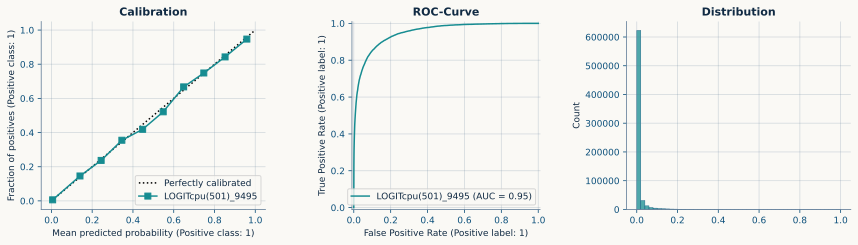

In [113]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 3.5))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [114]:
np1 = [2.5, 60.4, 56.9, 305.67]
np2 = [61.3, 5.7, 2.5]
padded_pairs = list(itertools.zip_longest(np1, np2, fillvalue=0))
np.mean(padded_pairs, axis=1)

array([ 31.9  ,  33.05 ,  29.7  , 152.835])

In [ ]:
top_n  = 30

df = feat_importances[0]
df = df.merge(feat_importances[1], how='left', on='feature')
df = df.merge(feat_importances[2], how='left', on='feature')
df = df.merge(feat_importances[3], how='left', on='feature')
df = df.merge(feat_importances[4], how='left', on='feature')
df['avg_score'] = df.iloc[:, -5:].mean(axis=1)
# df['avg_X_std'] = df['avg_score'] * df['avg_score'].std()
display(df.head())

# - Plot feature coef weights --
x = 'avg_X_std' if 'avg_X_std' in df.columns else 'avg_score'
df = df.sort_values(by=x, ascending=False).head(top_n)

plt.figure(figsize=(12, len(df)*0.25))
sns.barplot(data=df, x=x, y="feature", palette='plasma')
plt.title(f"{n}: Avg. {FOLDS}-Fold feature importances ({x})",loc='left')

plt.tight_layout()
plt.show()
    # break

In [116]:
try:
    import shap
except:
    !uv pip install shap
    import shap

print(f"Shap version: {shap.__version__}")

Shap version: 0.54.1


In [ ]:
feat_names = model.named_steps['columntransformer'].get_feature_names_out()
print(f"Model pipeline features: {len(feat_names)}")

_ = [c for c in X_val.columns if 'amount' in c]
display(X_val[_].head(3))

_ = [c for c in feat_names if 'amount' in c]
x_val = pd.DataFrame(model[:-1].transform(X_val), index=X_val.index, columns=feat_names)
x_val[_].head(3)

In [118]:
# Randomly select 100 rows without replacement
rng = np.random.default_rng(seed=101)
indices = rng.choice(x_val.shape[0], size=100, replace=False)
val_x = x_val.to_numpy()[indices]
val_y = y_val[indices]

## -- Shap Explainer --
def f(x):
    return model[-1].predict_proba(x)[:, 1]

val_y

array([0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int8)

In [ ]:
_id = 2
MAX = 20

explainer   = shap.Explainer(f, val_x, feature_names=feat_names, seed=42)
explanation = explainer(val_x, max_evals=max(500, 2*val_x.shape[1]+1))

## -- Bar plot --
plt.subplot(121)
shap.plots.bar(explanation[_id], max_display=MAX, show=False)
plt.title(f"Impact on model predictions for label {val_y[_id]}")

## -- Beeswarm plot --
plt.subplot(122)
shap.plots.beeswarm(
    explanation,
    order=explanation.abs.max(0),
    plot_size=(18, 8),
    max_display=MAX,
    color_bar=False,
    show=False,
)

plt.title("Beeswarm - Most impactful features")
plt.suptitle(f"{n}: SHAP Explainer", size=12, weight="semibold")
plt.tight_layout(pad=1.5)
plt.show()

print()